# 05 - Classificação com CNN

Treinamento de uma CNN simples (convoluções + camadas densas) para classificar os espectrogramas (já com CLAHE + contraste, em `mod_spectograms`) nas quatro classes: `ictal`, `normal`, `pos_ictal` e `pre_ictal`. A divisão treino/validação segue o `splits.csv`.

Os outros dois modelos estão em notebooks separados:
- `05_fcnn_classification.ipynb`: FCNN (Fully Convolutional Network)
- `05_encoder_decoder_classification.ipynb`: Encoder-Decoder

A avaliação dos três no conjunto de teste está no notebook `06_metrics.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1795056971.269903  185164 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']
(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3))) # Convolucao 2D
model.add(MaxPooling2D((2, 2))) # Camada de coarsen
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))

model.summary()

/home/orlandomota/miniconda3/envs/epilepsy-detection/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1795056975.198105  185164 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5131 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:06:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


I0000 00:00:1795056977.115639  185333 service.cc:153] XLA service 0x72cb64005270 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795056977.115662  185333 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795056977.150949  185333 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795056977.308972  185333 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795056977.342245  185333 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1986__.40
I0000 00:00:1795056983.247540  185333 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1795056983.527294  185333 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1986__.40


4/4 - 12s - 3s/step - accuracy: 0.1800 - loss: 1.5628 - val_accuracy: 0.3000 - val_loss: 1.3538
Epoch 2/30
4/4 - 0s - 48ms/step - accuracy: 0.3600 - loss: 1.3677 - val_accuracy: 0.3500 - val_loss: 1.3639
Epoch 3/30
4/4 - 0s - 44ms/step - accuracy: 0.3500 - loss: 1.3666 - val_accuracy: 0.4000 - val_loss: 1.3113
Epoch 4/30
4/4 - 0s - 44ms/step - accuracy: 0.4400 - loss: 1.3070 - val_accuracy: 0.4500 - val_loss: 1.1978
Epoch 5/30
4/4 - 0s - 44ms/step - accuracy: 0.4400 - loss: 1.2477 - val_accuracy: 0.5000 - val_loss: 1.1707
Epoch 6/30
4/4 - 0s - 43ms/step - accuracy: 0.4400 - loss: 1.1962 - val_accuracy: 0.4500 - val_loss: 1.1809
Epoch 7/30
4/4 - 0s - 44ms/step - accuracy: 0.5100 - loss: 1.1136 - val_accuracy: 0.4000 - val_loss: 1.1716
Epoch 8/30
4/4 - 0s - 43ms/step - accuracy: 0.6000 - loss: 0.9994 - val_accuracy: 0.4500 - val_loss: 1.1376
Epoch 9/30
4/4 - 0s - 43ms/step - accuracy: 0.6100 - loss: 0.8830 - val_accuracy: 0.5000 - val_loss: 1.1837
Epoch 10/30
4/4 - 0s - 42ms/step - accur

In [5]:
print(f"Acurácia final de treinamento: {history.history['accuracy'][-1]:.4f}")
print(f"Acurácia final de validação:   {history.history['val_accuracy'][-1]:.4f}")
print(f"Loss final de treinamento:     {history.history['loss'][-1]:.4f}")
print(f"Loss final de validação:       {history.history['val_loss'][-1]:.4f}")

Acurácia final de treinamento: 0.9800
Acurácia final de validação:   0.3000
Loss final de treinamento:     0.0755
Loss final de validação:       4.5205


## Gráficos

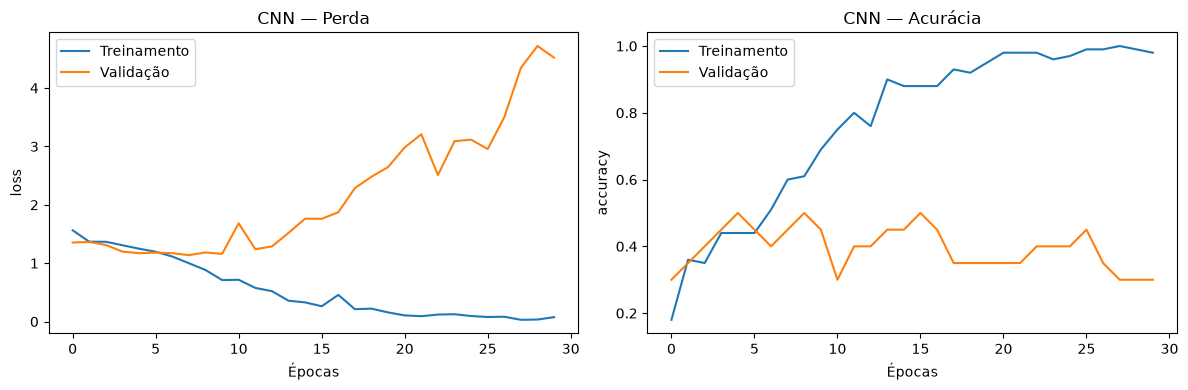

In [6]:
plotar_historico(history, 'CNN')

## Resultados (CNN)

A acurácia de treino sobe de 18% para 98% a 100%, e a loss de treino cai de 1,56 para 0,08. A validação não acompanha: a acurácia fica entre 30% e 50% (o melhor valor, 50%, aparece nas épocas 5, 9 e 16) e termina em 30%. A loss de validação cai até cerca de 1,14 na época 8 e depois só sobe, chegando a 4,5 na época 30.

Isso é overfitting. A rede tem cerca de 11 milhões de parâmetros para só 100 imagens de treino, e a partir da época 8 ela começa a decorar o treino. Com 20 imagens de validação, cada imagem vale 5 pontos percentuais, por isso a curva oscila tanto. Se o treino parasse perto da época 8 (com `EarlyStopping` monitorando a `val_loss`), o modelo salvo seria melhor que o da época 30.

## Salvando o modelo

In [7]:
model.save(PROJECT_ROOT / 'models' / 'modelo_cnn.keras')

## Perguntas (CNN)

**O que faz o otimizador Adam?**
Ele atualiza os pesos da rede usando o gradiente da loss, mas cada peso tem a sua própria taxa de aprendizado, que vai se ajustando durante o treino. Ele junta duas ideias: momentum (usa a média dos gradientes anteriores para suavizar a direção da atualização) e RMSProp (usa a média dos gradientes ao quadrado para controlar o tamanho do passo). Costuma convergir rápido e funciona bem sem precisar ajustar muito os hiperparâmetros.

**Por que a camada final utiliza Softmax?**
Porque o problema tem 4 classes e cada imagem pertence a só uma delas. A softmax transforma as 4 saídas em probabilidades que somam 1, e a classe prevista é a de maior probabilidade. Ela também é o tipo de saída que a `sparse_categorical_crossentropy` espera.

**Quantas camadas convolucionais existem?**
3 (`Conv2D` com 32, 64 e 128 filtros).

**Quantas camadas de pooling existem?**
3 (`MaxPooling2D` 2x2 após cada convolução).

**Quantos parâmetros possui a rede?**
11.169.476 parâmetros treináveis:

| Camada | Saída | Parâmetros |
|---|---|---|
| Conv2D (32) | 222x222x32 | 3x3x3x32 + 32 = 896 |
| MaxPooling2D | 111x111x32 | 0 |
| Conv2D (64) | 109x109x64 | 3x3x32x64 + 64 = 18.496 |
| MaxPooling2D | 54x54x64 | 0 |
| Conv2D (128) | 52x52x128 | 3x3x64x128 + 128 = 73.856 |
| MaxPooling2D | 26x26x128 | 0 |
| Flatten | 86.528 | 0 |
| Dense (128) | 128 | 86.528x128 + 128 = 11.075.712 |
| Dropout | 128 | 0 |
| Dense (4) | 4 | 128x4 + 4 = 516 |

Quase tudo (99%) está na primeira camada densa, por causa do Flatten de 86.528 valores.

**Qual camada é responsável pela classificação final?**
A última `Dense(4, activation='softmax')`, que gera a probabilidade de cada uma das 4 classes.

## Próximo passo

A avaliação no conjunto de teste está no notebook `06_metrics.ipynb`.